In [1]:
!nvidia-smi -L
!pip -q install einops lpips pytorch-msssim
!git clone -q https://github.com/swz30/Restormer.git
!cp Restormer/basicsr/models/archs/restormer_arch.py .
import os
assert os.path.exists('restormer_arch.py'), 'Restormer architecture file not found'
print('Setup OK')

GPU 0: Tesla T4 (UUID: GPU-ba7dd891-8128-e96d-2513-617439b7ec68)
Setup OK


In [2]:
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

DATA_ROOT = '/content/fog_dataset'
SAVE_DIR  = '/content/fog_checkpoints'
SYNTHETIC = False
PATCH     = 128
BATCH     = 4
EPOCHS    = 150
LR        = 2e-4
SEED      = 42
os.makedirs(SAVE_DIR, exist_ok=True)

In [3]:
!wget -q -O /content/NH-HAZE.zip https://data.vision.ee.ethz.ch/cvl/vision2/ntire20/nh-haze/files/NH-HAZE.zip
!unzip -q -o /content/NH-HAZE.zip -d /content/nh

import glob, shutil
root = DATA_ROOT + '/train'
os.makedirs(root + '/GT', exist_ok=True); os.makedirs(root + '/Foggy', exist_ok=True)
for p in glob.glob('/content/nh/**/*', recursive=True):
    n = os.path.basename(p).lower()
    if not n.endswith(('.png', '.jpg', '.jpeg')): continue
    if 'gt' in n:     shutil.copy(p, root + '/GT/' + os.path.basename(p))
    elif 'hazy' in n: shutil.copy(p, root + '/Foggy/' + os.path.basename(p))
print('GT:', len(os.listdir(root + '/GT')), '| Foggy:', len(os.listdir(root + '/Foggy')))

GT: 55 | Foggy: 55


In [4]:
import glob, random, math
import numpy as np, cv2, torch
from torch.utils.data import Dataset, DataLoader

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
EXT = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')

def list_imgs(d):
    return sorted(p for p in glob.glob(os.path.join(d, '*')) if p.lower().endswith(EXT))

def find_pairs(split_dir, synthetic):
    gts = list_imgs(os.path.join(split_dir, 'GT'))
    if synthetic:
        return [(None, g) for g in gts]
    foggy = list_imgs(os.path.join(split_dir, 'Foggy'))
    stem_of = lambda p: os.path.splitext(os.path.basename(p))[0]
    gt_by_stem = {stem_of(g): g for g in gts}
    gt_by_id = {}
    for g in gts: gt_by_id.setdefault(stem_of(g).split('_')[0], g)
    pairs = []
    for f in foggy:
        st = stem_of(f)
        g = gt_by_stem.get(st) or gt_by_id.get(st.split('_')[0])
        if g: pairs.append((f, g))
    print('matched', len(pairs), 'of', len(foggy), 'foggy images')
    return pairs

train_pairs = find_pairs(os.path.join(DATA_ROOT, 'train'), SYNTHETIC)
val_dir = os.path.join(DATA_ROOT, 'val')
if os.path.isdir(val_dir):
    val_pairs = find_pairs(val_dir, SYNTHETIC)
else:
    random.shuffle(train_pairs)
    k = max(1, len(train_pairs) // 20)
    val_pairs, train_pairs = train_pairs[:k], train_pairs[k:]
print(f'train pairs: {len(train_pairs)} | val pairs: {len(val_pairs)}')
assert len(train_pairs) > 0, 'No training images found.'

def synth_fog(j, rng=np.random):
    h, w = j.shape[:2]
    y = np.linspace(1.0, 0.0, h, dtype=np.float32)[:, None]
    depth = 0.3 + 0.7 * np.repeat(y, w, axis=1)
    blob = cv2.resize(rng.rand(4, 4).astype(np.float32), (w, h), interpolation=cv2.INTER_CUBIC)
    depth = np.clip(depth + 0.3 * (blob - 0.5), 0.05, 1.5)
    beta = rng.uniform(0.8, 2.8); A = rng.uniform(0.7, 1.0)
    t = np.exp(-beta * depth)[..., None]
    out = j * t + A * (1 - t)
    out += rng.normal(0, rng.uniform(0, 0.02), out.shape).astype(np.float32)
    return np.clip(out, 0, 1).astype(np.float32)

def read_rgb(p):
    im = cv2.imread(p, cv2.IMREAD_COLOR)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

class FogDS(Dataset):
    def __init__(self, pairs, train=True, synthetic=False, patch=PATCH, val_size=384):
        self.pairs, self.train, self.synthetic = pairs, train, synthetic
        self.patch = patch if train else val_size
    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        fp, gp = self.pairs[i]
        gt = read_rgb(gp)
        fg = None if self.synthetic else read_rgb(fp)
        if fg is not None and fg.shape != gt.shape:
            fg = cv2.resize(fg, (gt.shape[1], gt.shape[0]))
        h, w = gt.shape[:2]; p = self.patch
        if min(h, w) < p:
            s = p / min(h, w)
            gt = cv2.resize(gt, (math.ceil(w*s), math.ceil(h*s)))
            if fg is not None: fg = cv2.resize(fg, (gt.shape[1], gt.shape[0]))
            h, w = gt.shape[:2]
        if self.train: y, x = random.randint(0, h-p), random.randint(0, w-p)
        else:          y, x = (h-p)//2, (w-p)//2
        gt = gt[y:y+p, x:x+p]
        fg = synth_fog(gt) if self.synthetic else fg[y:y+p, x:x+p]
        if self.train:
            if random.random() < 0.5: gt, fg = gt[:, ::-1], fg[:, ::-1]
            if random.random() < 0.5: gt, fg = gt[::-1], fg[::-1]
        f = lambda a: torch.from_numpy(np.ascontiguousarray(a.transpose(2, 0, 1)))
        return f(fg), f(gt)

train_dl = DataLoader(FogDS(train_pairs, True, SYNTHETIC), batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True, pin_memory=True)
val_dl   = DataLoader(FogDS(val_pairs, False, SYNTHETIC), batch_size=1, shuffle=False, num_workers=2)

matched 55 of 55 foggy images
train pairs: 53 | val pairs: 2


In [5]:
from restormer_arch import Restormer

def build(norm):
    return Restormer(inp_channels=3, out_channels=3, dim=48, num_blocks=[4,6,6,8], num_refinement_blocks=4,
                     heads=[1,2,4,8], ffn_expansion_factor=2.66, bias=False, LayerNorm_type=norm, dual_pixel_task=False)

device = 'cuda'
url = 'https://github.com/swz30/Restormer/releases/download/v1.0/real_denoising.pth'
!wget -q -O pretrained.pth {url}

model, used_norm = None, None
try:
    ck = torch.load('pretrained.pth', map_location='cpu')
    sd = ck.get('params', ck)
    best_missing = 10**9
    for norm in ['BiasFree', 'WithBias']:
        m = build(norm)
        res = m.load_state_dict(sd, strict=False)
        if len(res.missing_keys) < best_missing:
            best_missing, model, used_norm = len(res.missing_keys), m, norm
    print(f'Loaded pretrained weights ({used_norm}); missing keys: {best_missing}')
except Exception as e:
    print('Could not load pretrained weights, training from scratch:', e)
    used_norm = 'WithBias'; model = build(used_norm)
model = model.to(device)
print(f'Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f} M')

Loaded pretrained weights (BiasFree); missing keys: 0
Parameters: 26.1 M


In [6]:
import lpips, time
from pytorch_msssim import ssim as ssim_fn

def charbonnier(p, t, eps=1e-3): return torch.sqrt((p - t) ** 2 + eps ** 2).mean()
def fft_l1(p, t): return (torch.fft.rfft2(p, norm='ortho') - torch.fft.rfft2(t, norm='ortho')).abs().mean()
def psnr(p, t): return (-10 * torch.log10(((p - t) ** 2).mean().clamp_min(1e-10))).item()

lp = lpips.LPIPS(net='alex').to(device).eval()
opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.999), weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(train_dl), eta_min=1e-6)
scaler = torch.cuda.amp.GradScaler()

@torch.no_grad()
def validate():
    model.eval(); P = S = L = 0
    for x, y in val_dl:
        x, y = x.to(device), y.to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            o = model(x)
        o = o.float().clamp(0, 1)
        P += psnr(o, y); S += ssim_fn(o, y, data_range=1.0).item()
        L += lp(o * 2 - 1, y * 2 - 1).mean().item()
    n = len(val_dl); return P / n, S / n, L / n

best_psnr = 0
for ep in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); run = 0
    for x, y in train_dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast('cuda', dtype=torch.float16):
            o = model(x)
        o = o.float()
        loss = charbonnier(o, y) + 0.1 * fft_l1(o, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        run += loss.item()
    if ep % 5 == 0 or ep == 1:
        P, S, L = validate()
        print(f'Epoch {ep}/{EPOCHS} | loss {run/len(train_dl):.4f} | PSNR {P:.2f} dB | SSIM {S:.4f} | LPIPS {L:.4f} | {time.time()-t0:.0f}s')
        ckpt = {'epoch': ep, 'model': model.state_dict(), 'norm': used_norm, 'psnr': P, 'ssim': S, 'lpips': L}
        torch.save(ckpt, os.path.join(SAVE_DIR, 'last.pth'))
        if P > best_psnr:
            best_psnr = P
            torch.save(ckpt, os.path.join(SAVE_DIR, 'best.pth'))
            print('  saved best.pth')

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 166MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


/tmp/ipykernel_348/3617631135.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Epoch 1/150 | loss 0.2318 | PSNR 12.44 dB | SSIM 0.4998 | LPIPS 0.4431 | 19s
  saved best.pth
Epoch 5/150 | loss 0.1545 | PSNR 11.48 dB | SSIM 0.4520 | LPIPS 0.4881 | 11s
Epoch 10/150 | loss 0.1477 | PSNR 11.21 dB | SSIM 0.5500 | LPIPS 0.4296 | 11s
Epoch 15/150 | loss 0.1505 | PSNR 12.72 dB | SSIM 0.6074 | LPIPS 0.3755 | 11s
  saved best.pth
Epoch 20/150 | loss 0.1584 | PSNR 13.44 dB | SSIM 0.5725 | LPIPS 0.3881 | 11s
  saved best.pth
Epoch 25/150 | loss 0.1358 | PSNR 12.65 dB | SSIM 0.5973 | LPIPS 0.3623 | 11s
Epoch 30/150 | loss 0.1160 | PSNR 12.49 dB | SSIM 0.5965 | LPIPS 0.3618 | 12s
Epoch 35/150 | loss 0.1169 | PSNR 13.82 dB | SSIM 0.6259 | LPIPS 0.3333 | 11s
  saved best.pth
Epoch 40/150 | loss 0.1369 | PSNR 12.63 dB | SSIM 0.6038 | LPIPS 0.3412 | 12s
Epoch 45/150 | loss 0.1120 | PSNR 12.60 dB | SSIM 0.5909 | LPIPS 0.3546 | 11s
Epoch 50/150 | loss 0.1167 | PSNR 13.13 dB | SSIM 0.6064 | LPIPS 0.3356 | 11s
Epoch 55/150 | loss 0.1187 | PSNR 12.77 dB | SSIM 0.6076 | LPIPS 0.3506 | 11

best.pth: epoch 80 | PSNR 14.23 | SSIM 0.6312 | LPIPS 0.3276


Saving 360_F_801486219_9cGKHfloqMCI1pbPWJXFGFzUhXG3YDWT.jpg to 360_F_801486219_9cGKHfloqMCI1pbPWJXFGFzUhXG3YDWT.jpg


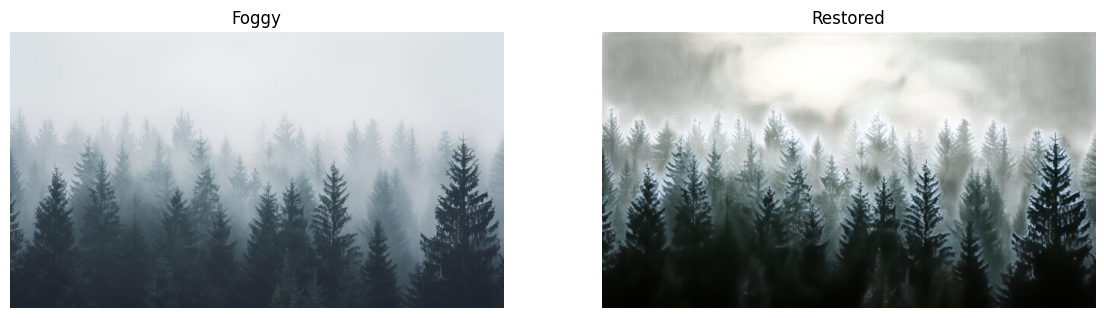

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from google.colab import files
import matplotlib.pyplot as plt

ck = torch.load(os.path.join(SAVE_DIR, 'best.pth'), map_location=device)
model.load_state_dict(ck['model']); model.eval()
print(f"best.pth: epoch {ck['epoch']} | PSNR {ck['psnr']:.2f} | SSIM {ck['ssim']:.4f} | LPIPS {ck['lpips']:.4f}")

@torch.no_grad()
def defog(img, max_side=1280):
    h, w = img.shape[:2]
    s = min(1.0, max_side / max(h, w))
    if s < 1: img = cv2.resize(img, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]
    ph, pw = (8 - h % 8) % 8, (8 - w % 8) % 8
    x = torch.from_numpy(img.transpose(2, 0, 1)).unsqueeze(0).to(device)
    x = torch.nn.functional.pad(x, (0, pw, 0, ph), mode='reflect')
    with torch.autocast('cuda', dtype=torch.float16):
        o = model(x)
    return o.float().clamp(0, 1)[0, :, :h, :w].cpu().numpy().transpose(1, 2, 0)

up = files.upload()
for name in up:
    img = read_rgb(name)
    out = defog(img)
    outname = 'defogged_' + os.path.splitext(name)[0] + '.png'
    cv2.imwrite(outname, cv2.cvtColor((out * 255).astype(np.uint8), cv2.COLOR_RGB2BGR))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    ax[0].imshow(img); ax[0].set_title('Foggy'); ax[1].imshow(out); ax[1].set_title('Restored')
    for a in ax: a.axis('off')
    plt.show()
    files.download(outname)

In [8]:
import gc
for n in ['opt', 'sched', 'scaler', 'lp', 'train_dl', 'val_dl', 'x', 'y', 'o', 'loss']:
    globals().pop(n, None)
gc.collect(); torch.cuda.empty_cache()
print('Free GPU memory (GB):', round(torch.cuda.mem_get_info()[0] / 1e9, 1))

Free GPU memory (GB): 14.7


In [9]:
%%writefile /content/page.html
<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>ClearView – Fog Remover</title>
<link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;800&display=swap" rel="stylesheet">
<style>
:root{--bg:#f3f8ff;--glass:rgba(255,255,255,.72);--line:rgba(60,90,150,.16);--text:#1b2740;--muted:#5b6b86;--a:#4a90ff;--b:#7c8cff}
*{box-sizing:border-box}
body{margin:0;min-height:100vh;background:linear-gradient(180deg,#eef5ff 0%,#f8fbff 55%,#ffffff 100%);color:var(--text);font-family:Inter,system-ui,sans-serif;overflow-x:hidden}
.fog{position:fixed;inset:0;z-index:0;pointer-events:none;overflow:hidden}
.fog i{position:absolute;border-radius:50%;filter:blur(80px);opacity:.55;animation:drift 18s ease-in-out infinite alternate}
.fog i:nth-child(1){width:520px;height:520px;background:#bcd8ff;left:-120px;top:-120px}
.fog i:nth-child(2){width:600px;height:600px;background:#d9ccff;right:-160px;top:20%;animation-duration:24s}
.fog i:nth-child(3){width:480px;height:480px;background:#c3f1e6;left:30%;bottom:-220px;animation-duration:21s}
@keyframes drift{to{transform:translate(60px,40px) scale(1.15)}}
.wrap{position:relative;z-index:1;max-width:1000px;margin:0 auto;padding:28px 20px 60px}
nav{display:flex;align-items:center;gap:10px;font-weight:800;font-size:1.15rem}
nav .logo{width:34px;height:34px;border-radius:10px;background:linear-gradient(135deg,var(--a),var(--b));display:grid;place-items:center;box-shadow:0 6px 16px rgba(74,144,255,.35)}
.hero{text-align:center;padding:56px 0 34px}
.badge{display:inline-block;padding:6px 14px;border:1px solid var(--line);background:rgba(255,255,255,.8);border-radius:99px;font-size:.8rem;color:var(--muted)}
h1{font-size:clamp(2.2rem,6vw,3.8rem);line-height:1.08;margin:18px 0 14px;font-weight:800;letter-spacing:-.02em;color:#17233d}
h1 span{background:linear-gradient(90deg,#3b82f6,#8b7cf6,#14b8a6);-webkit-background-clip:text;background-clip:text;color:transparent}
.sub{max-width:560px;margin:0 auto;color:var(--muted);font-size:1.05rem;line-height:1.6}
.card{background:var(--glass);border:1px solid var(--line);border-radius:22px;padding:22px;backdrop-filter:blur(14px);-webkit-backdrop-filter:blur(14px);box-shadow:0 18px 50px rgba(60,100,180,.14)}
.drop{border:2px dashed rgba(74,144,255,.45);border-radius:16px;padding:54px 18px;text-align:center;cursor:pointer;transition:.25s;background:rgba(255,255,255,.55)}
.drop:hover,.drop.over{border-color:var(--a);background:rgba(74,144,255,.09);transform:translateY(-2px)}
.drop .ic{font-size:2.6rem;margin-bottom:8px}
.drop b{font-size:1.1rem}.drop p{color:var(--muted);margin:6px 0 0;font-size:.9rem}
.cmp{position:relative;border-radius:16px;overflow:hidden;cursor:ew-resize;touch-action:none;user-select:none;background:#e6eefb;box-shadow:0 8px 28px rgba(60,100,180,.18)}
.cmp img{display:block;width:100%;height:auto}
.cmp img.after{position:absolute;inset:0;height:100%}
.tag{position:absolute;top:12px;padding:4px 12px;border-radius:99px;background:rgba(20,30,55,.62);color:#fff;backdrop-filter:blur(6px);font-size:.75rem;font-weight:600}
.tag.l{left:12px}.tag.r{right:12px}
.handle{position:absolute;top:0;bottom:0;width:3px;background:#fff;transform:translateX(-50%);box-shadow:0 0 12px rgba(0,0,0,.35)}
.handle b{position:absolute;top:50%;left:50%;transform:translate(-50%,-50%);width:42px;height:42px;border-radius:50%;background:#fff;color:#2b4a8a;display:grid;place-items:center;box-shadow:0 4px 16px rgba(0,0,0,.3)}
.busy{position:absolute;inset:0;background:rgba(240,246,255,.78);backdrop-filter:blur(4px);display:grid;place-content:center;justify-items:center;gap:14px;font-weight:600;color:#1b2740}
.spin{width:46px;height:46px;border-radius:50%;border:4px solid rgba(74,144,255,.22);border-top-color:var(--a);animation:sp .9s linear infinite}
@keyframes sp{to{transform:rotate(360deg)}}
.bar{display:flex;flex-wrap:wrap;gap:10px;align-items:center;justify-content:space-between;margin-top:16px}
.stats{display:flex;gap:10px;flex-wrap:wrap}
.chip{padding:6px 12px;border-radius:99px;border:1px solid var(--line);background:rgba(255,255,255,.8);font-size:.8rem;color:var(--muted)}
.btns{display:flex;gap:10px}
.btn{border:0;border-radius:12px;padding:11px 20px;font:600 .95rem Inter,sans-serif;cursor:pointer;text-decoration:none;color:#fff;background:linear-gradient(135deg,var(--a),var(--b));box-shadow:0 8px 20px rgba(74,144,255,.32);transition:.2s}
.btn:hover{transform:translateY(-1px);filter:brightness(1.06)}
.btn.ghost{background:#fff;border:1px solid var(--line);color:var(--text);box-shadow:none}
.err{margin-top:14px;padding:12px 14px;border-radius:12px;background:#fff1f1;border:1px solid #f5b5b5;color:#b42323;font-size:.9rem}
.steps{display:grid;grid-template-columns:repeat(auto-fit,minmax(240px,1fr));gap:16px;margin-top:34px}
.step{padding:20px}.step .n{width:34px;height:34px;border-radius:10px;display:grid;place-items:center;font-weight:800;color:#fff;background:linear-gradient(135deg,var(--a),var(--b));margin-bottom:12px}
.step h3{margin:0 0 6px;font-size:1.05rem}.step p{margin:0;color:var(--muted);font-size:.92rem;line-height:1.55}
footer{text-align:center;color:var(--muted);font-size:.82rem;margin-top:40px}
</style></head><body>
<div class="fog"><i></i><i></i><i></i></div>
<div id="root"></div>
<script src="https://cdnjs.cloudflare.com/ajax/libs/react/18.3.1/umd/react.production.min.js"></script>
<script src="https://cdnjs.cloudflare.com/ajax/libs/react-dom/18.3.1/umd/react-dom.production.min.js"></script>
<script src="https://cdnjs.cloudflare.com/ajax/libs/babel-standalone/7.23.9/babel.min.js"></script>
<script type="text/babel">
const {useState,useRef}=React;

function Compare({before,after,busy}){
  const box=useRef(null),drag=useRef(false);
  const [pos,setPos]=useState(50);
  const move=e=>{const r=box.current.getBoundingClientRect();setPos(Math.min(100,Math.max(0,(e.clientX-r.left)/r.width*100)))};
  return (
    <div className="cmp" ref={box}
      onPointerDown={e=>{drag.current=true;e.currentTarget.setPointerCapture(e.pointerId);move(e)}}
      onPointerMove={e=>drag.current&&move(e)} onPointerUp={()=>drag.current=false}>
      <img src={before} draggable="false" alt="Foggy"/>
      {after&&<img className="after" src={after} draggable="false" alt="Restored" style={{clipPath:`inset(0 0 0 ${pos}%)`}}/>}
      {after&&<><span className="tag l">Foggy</span><span className="tag r">Restored</span>
        <div className="handle" style={{left:pos+"%"}}><b>⇆</b></div></>}
      {busy&&<div className="busy"><div className="spin"></div><div>Removing fog…</div></div>}
    </div>);
}

function App(){
  const [before,setBefore]=useState(null),[after,setAfter]=useState(null);
  const [busy,setBusy]=useState(false),[err,setErr]=useState(""),[info,setInfo]=useState(null),[over,setOver]=useState(false);
  const input=useRef(null);

  async function run(f){
    if(!f||!f.type.startsWith("image/")){setErr("Please choose an image file.");return}
    setErr("");setAfter(null);setInfo(null);setBusy(true);
    const url=URL.createObjectURL(f);setBefore(url);
    const im=new Image();im.src=url;await im.decode().catch(()=>{});
    const t0=performance.now();
    try{
      const fd=new FormData();fd.append("image",f);
      const r=await fetch("/defog",{method:"POST",body:fd});
      if(!r.ok)throw new Error(await r.text());
      const out=URL.createObjectURL(await r.blob());
      setAfter(out);
      setInfo({s:((performance.now()-t0)/1000).toFixed(1),w:im.naturalWidth,h:im.naturalHeight});
    }catch(e){setErr("Something went wrong: "+e.message)}
    setBusy(false);
  }
  const reset=()=>{setBefore(null);setAfter(null);setInfo(null);setErr("");if(input.current)input.current.value=""};

  return (
    <div className="wrap">
      <nav><div className="logo">🌫️</div>ClearView</nav>
      <div className="hero">
        <span className="badge">Powered by Restormer · fine-tuned on foggy image pairs</span>
        <h1>See through <span>the fog</span></h1>
        <p className="sub">Upload a foggy photo and our deep-learning model restores contrast, detail and colour in seconds.</p>
      </div>

      <div className="card">
        {!before ? (
          <div className={"drop"+(over?" over":"")} onClick={()=>input.current.click()}
            onDragOver={e=>{e.preventDefault();setOver(true)}} onDragLeave={()=>setOver(false)}
            onDrop={e=>{e.preventDefault();setOver(false);run(e.dataTransfer.files[0])}}>
            <div className="ic">☁️</div><b>Drop a foggy image here</b>
            <p>or click to browse · JPG, PNG, WebP</p>
          </div>
        ) : (
          <>
            <Compare before={before} after={after} busy={busy}/>
            <div className="bar">
              <div className="stats">
                {info&&<><span className="chip">⏱ {info.s}s</span><span className="chip">🖼 {info.w}×{info.h}</span></>}
                {after&&<span className="chip">Drag the slider to compare</span>}
              </div>
              <div className="btns">
                <button className="btn ghost" onClick={reset} disabled={busy}>New image</button>
                {after&&<a className="btn" href={after} download="defogged.png">Download</a>}
              </div>
            </div>
          </>
        )}
        <input ref={input} type="file" accept="image/*" hidden onChange={e=>run(e.target.files[0])}/>
        {err&&<div className="err">{err}</div>}
      </div>

      <div className="steps">
        {[["Upload","Drop in any foggy or hazy photo from your device."],
          ["Restore","A Transformer-based Restormer model removes haze and recovers detail."],
          ["Compare","Slide between the foggy and restored versions, then download."]].map((s,i)=>
          <div className="card step" key={i}><div className="n">{i+1}</div><h3>{s[0]}</h3><p>{s[1]}</p></div>)}
      </div>
      <footer>AI-Based Noise Removal in Foggy Images · Restormer</footer>
    </div>);
}
ReactDOM.createRoot(document.getElementById("root")).render(<App/>);
</script></body></html>

Writing /content/page.html


In [10]:
!pip -q install flask pillow
import io, os, threading
import numpy as np, torch
from PIL import Image
from flask import Flask, request, send_file
from restormer_arch import Restormer

MAX_SIDE = 1024            # lower to 768 if you get out-of-memory errors
CKPT = '/content/fog_checkpoints/best.pth'
device = 'cuda'

ck = torch.load(CKPT, map_location=device)
model = Restormer(inp_channels=3, out_channels=3, dim=48, num_blocks=[4,6,6,8], num_refinement_blocks=4,
                  heads=[1,2,4,8], ffn_expansion_factor=2.66, bias=False,
                  LayerNorm_type=ck.get('norm', 'WithBias'), dual_pixel_task=False).to(device)
model.load_state_dict(ck['model']); model.eval()
print(f"Loaded best.pth (epoch {ck['epoch']}, PSNR {ck['psnr']:.2f} dB)")

@torch.no_grad()
def defog(img):
    h, w = img.shape[:2]
    s = min(1.0, MAX_SIDE / max(h, w))
    if s < 1:
        img = np.array(Image.fromarray((img * 255).astype(np.uint8)).resize((int(w*s), int(h*s)), Image.LANCZOS), dtype=np.float32) / 255
    h, w = img.shape[:2]
    ph, pw = (8 - h % 8) % 8, (8 - w % 8) % 8
    x = torch.from_numpy(img.transpose(2, 0, 1)).unsqueeze(0).to(device)
    x = torch.nn.functional.pad(x, (0, pw, 0, ph), mode='reflect')
    with torch.autocast('cuda', dtype=torch.float16):
        o = model(x)
    return o.float().clamp(0, 1)[0, :, :h, :w].cpu().numpy().transpose(1, 2, 0)

app = Flask(__name__)

@app.route('/')
def index():
    return send_file('/content/page.html')

@app.route('/defog', methods=['POST'])
def defog_route():
    try:
        img = np.array(Image.open(request.files['image'].stream).convert('RGB'), dtype=np.float32) / 255
        out = defog(img)
        buf = io.BytesIO()
        Image.fromarray((out * 255).round().astype(np.uint8)).save(buf, 'PNG')
        buf.seek(0)
        return send_file(buf, mimetype='image/png')
    except Exception as e:
        torch.cuda.empty_cache()
        return str(e), 500

threading.Thread(target=lambda: app.run(host='0.0.0.0', port=5000, use_reloader=False), daemon=True).start()
print('Server started on port 5000')

Loaded best.pth (epoch 80, PSNR 14.23 dB)
Server started on port 5000


In [11]:
import subprocess, re, time
!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared
log = open('cf.log', 'w')
subprocess.Popen(['./cloudflared', 'tunnel', '--url', 'http://localhost:5000'], stdout=log, stderr=subprocess.STDOUT)
url = None
for _ in range(30):
    time.sleep(1)
    m = re.search(r'https://[-a-z0-9]+\.trycloudflare\.com', open('cf.log').read())
    if m: url = m.group(0); break
print('Open this link:', url or 'not found, run: !tail cf.log')

Open this link: https://provinces-satellite-san-roster.trycloudflare.com


In [ ]:
from google.colab import output
output.serve_kernel_port_as_window(5000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>